# Portfolio Construction and Asset Pricing Tests for the ViT Signal

This notebook answers two questions about the ViT model's predictions:

1. **Does the signal make money?** Each month, stocks are sorted by firm size and by the model's
   P(up). We hold the resulting portfolios for one month, measure their returns after trading
   costs, and build a long-short "ViT factor" that buys high-signal stocks and sells low-signal ones.
2. **Is the signal new?** A factor that makes money might just be a known factor in disguise
   (momentum, profitability, low risk, ...). The double-selection LASSO of Feng, Giglio and Xiu
   (2020) tests whether the ViT factor still explains returns after controlling for 161
   established factors.

The method follows Byun, Na and Song (2026), *From vision to value*, Finance Research Letters 92,
109585, and their public code (github.com/finxlab/vit-sdf-lasso). Places where this notebook
deliberately differs from their code are marked **Note**.

## Inputs

Put these in one folder and set `DATA_DIR` in the settings cell.

| File | What it is | Where it comes from |
|---|---|---|
| `vit_signals_full.csv` | One row per test image: `path`, `true_label`, `predicted_label`, `prob_down`, `prob_up` | Output of `inference.ipynb` |
| `crsp_daily.csv` | CRSP daily stock file, June 2000 to July 2020, with columns `PERMNO`, `date`, `SHRCD`, `EXCHCD`, `PRC`, `VOL`, `SHROUT`, `RET` | WRDS (see below) |
| `processed_kelly/` folder | 153 Global Factor Data factors, Fama-French 3 and 5 factors, momentum, q-factors, and 1,958 test portfolios | The authors' GitHub repo (see below) |

**CRSP daily file.** On WRDS: CRSP, Stock / Security Files, Daily Stock File. Date range
2000-06-01 to 2020-07-31, all PERMNOs, and the variables listed above. `SHRCD` and `EXCHCD` come
from the header/names information; tick them in the query form if they are offered as extra
variables. Save as CSV.

**Factor files.** Open github.com/finxlab/vit-sdf-lasso, click **Code**, then **Download ZIP**.
Unzip it and copy the folder `sdf_analysis/data/processed_kelly` into `DATA_DIR`. The repo is
MIT licensed; the data inside comes from public sources (jkpfactors.com, global-q.org and
Kenneth French's data library).

## Outline

1. Settings
2. Load the ViT signals and keep one signal per stock per month
3. Load CRSP and build monthly returns, market caps and size breakpoints
4. Sort stocks into portfolios each month
5. Portfolio returns, the ViT factor and market benchmarks
6. Performance: return tables, risk metrics, cumulative returns, factor alphas
7. Double-selection LASSO against 161 factors
8. Save results

## 1. Settings

In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, lasso_path
from sklearn.model_selection import KFold
from tqdm import tqdm

warnings.filterwarnings("ignore", category=ConvergenceWarning)

# ---- Paths -------------------------------------------------------------------
DATA_DIR = "."                                            # folder holding the inputs
SIGNALS_CSV = os.path.join(DATA_DIR, "vit_signals_full_scratch.csv")
CRSP_DAILY_CSV = os.path.join(DATA_DIR, "us_920101-200731_adjusted_full.csv")
FACTOR_DIR = os.path.join(DATA_DIR, "processed_kelly")
OUT_DIR = os.path.join(DATA_DIR, "results")
os.makedirs(OUT_DIR, exist_ok=True)

# ---- Portfolio settings (from the paper) -------------------------------------
FEE = 0.001          # 10 bps charged when buying and again when selling (full monthly turnover)
NW_LAGS = 6          # Newey-West lags for t-statistics on monthly returns
CRSP_START = "2000-06-01"   # earliest CRSP date needed: June 2000 sets the first size breakpoints

# ---- LASSO settings (from the paper) -----------------------------------------
N_LAMBDAS = 100
LAMBDAS = np.exp(np.linspace(0, -35, N_LAMBDAS))   # penalty grid, largest first
N_FOLDS = 10
N_SEEDS = 200        # cross-validation repeats; 200 matches the paper. Use 20 for a quick first run.
N_JOBS = -1          # CPU cores for the LASSO step (-1 = all)

## 2. ViT signals

The inference CSV has one row per chart image. The file name inside `path` holds the stock's
CRSP identifier (PERMNO) and the chart's last day, e.g. `.../10001_20010315.png`. The signal is
`prob_up`, the model's probability that the price rises over the next 20 trading days.

The file has about 29 million rows, so it is read in chunks of 2 million and only the needed
columns are kept.

In [3]:
parts = []
for chunk in pd.read_csv(SIGNALS_CSV, usecols=["path", "prob_up"], chunksize=2_000_000):
    # Pull PERMNO and the date out of the file name at the end of the path
    ids = chunk["path"].str.extract(r"(\d+)_(\d{8})\.png$")
    parts.append(pd.DataFrame({
        "permno": ids[0].astype("int32"),
        "date": pd.to_datetime(ids[1], format="%Y%m%d"),
        "signal": chunk["prob_up"].astype("float32"),
    }))

signals = pd.concat(parts, ignore_index=True)
del parts

# The inference run was interrupted and resumed once, so check for repeated stock-days
n_dup = signals.duplicated(["permno", "date"]).sum()
signals = signals.drop_duplicates(["permno", "date"])

print(f"Signal rows: {len(signals):,} | duplicates removed: {n_dup:,}")
print(f"Stocks: {signals['permno'].nunique():,} | dates: {signals['date'].min().date()} to {signals['date'].max().date()}")

Signal rows: 29,331,050 | duplicates removed: 0
Stocks: 15,782 | dates: 2001-01-02 to 2020-07-02


## 3. CRSP data

The CRSP daily file gives us, for every stock and trading day: exchange, price, shares
outstanding, volume and daily return.

Filters, as in the paper: common stocks only (`SHRCD` 10 or 11) on NYSE, AMEX or NASDAQ
(`EXCHCD` 1, 2 or 3).

**Note.** `RET` is CRSP's total return, already adjusted for splits and dividends. Monthly
returns are built by compounding it, which is what the authors do. Raw `PRC` is only used for
market capitalisation. Delisting returns are not included, as in the authors' code.

In [5]:
NEEDED = ["PERMNO", "date", "EXCHCD", "PRC", "VOL", "SHROUT", "RET"]

header = pd.read_csv(CRSP_DAILY_CSV, nrows=0)
header.columns = header.columns.str.upper().str.strip()
missing = [c for c in NEEDED if c.upper() not in header.columns]
if missing:
    raise ValueError(f"The CRSP file is missing these columns: {missing}. Download them from WRDS.")

parts = []
for chunk in tqdm(pd.read_csv(CRSP_DAILY_CSV, chunksize=2_000_000, low_memory=False), desc="Reading CRSP"):
    chunk.columns = chunk.columns.str.upper().str.strip()
    chunk = chunk.rename(columns={"DATE": "date"})[NEEDED]

    chunk["date"] = pd.to_datetime(chunk["date"])
    chunk = chunk[chunk["date"] >= CRSP_START]

    chunk["EXCHCD"] = pd.to_numeric(chunk["EXCHCD"], errors="coerce")
    chunk = chunk[chunk["EXCHCD"].isin([1, 2, 3])]

    # RET contains letter codes (e.g. "C", "B") when no return exists; those become NaN
    ret = pd.to_numeric(chunk["RET"], errors="coerce")
    cap = pd.to_numeric(chunk["PRC"], errors="coerce").abs() * pd.to_numeric(chunk["SHROUT"], errors="coerce")

    parts.append(pd.DataFrame({
        "permno": chunk["PERMNO"].astype("int32"),
        "date": chunk["date"],
        "exchcd": chunk["EXCHCD"].astype("int8"),
        "cap": cap.astype("float64"),            # market cap in $ thousands
        "vol": pd.to_numeric(chunk["VOL"], errors="coerce").astype("float32"),
        "ret": ret.astype("float64"),
    }))

crsp = pd.concat(parts, ignore_index=True)
del parts
crsp["ym"] = crsp["date"].dt.to_period("M")

print(f"CRSP rows: {len(crsp):,} | stocks: {crsp['permno'].nunique():,} | {crsp['date'].min().date()} to {crsp['date'].max().date()}")

Reading CRSP: 0it [00:00, ?it/s]

Reading CRSP: 28it [02:11,  4.70s/it]


CRSP rows: 31,811,486 | stocks: 16,102 | 2000-06-01 to 2020-07-31


### Monthly building blocks

From the daily data we need four things per stock and month:

- **Month-end market cap** (`me`): market cap on the month's last trading day. Used for weights.
- **Month-end exchange** (`exchcd`): to find NYSE stocks for breakpoints.
- **Monthly return** (`mret`): daily returns compounded over the month. After a stock stops
  trading its return counts as zero, the same as the authors' forward-filled prices.
- **Tradable at the start** (`tradable`): volume above zero on the month's first trading day.
  The authors drop stocks that don't trade at the start of the holding month.

In [6]:
# Trading calendar: first and last trading day of each month
calendar = crsp.groupby("ym")["date"].agg(first_day="min", last_day="max")

# Month-end market cap and exchange (only stocks that have a row on the last trading day)
is_last_day = crsp["date"].values == crsp["ym"].map(calendar["last_day"]).values
month_end = (crsp.loc[is_last_day, ["permno", "ym", "cap", "exchcd"]]
             .dropna(subset=["cap"])
             .rename(columns={"cap": "me"})
             .set_index(["ym", "permno"]))

# Monthly compounded return
crsp["gross"] = 1.0 + crsp["ret"].fillna(0.0)
mret = (crsp.groupby(["ym", "permno"])["gross"].prod() - 1.0).rename("mret")

# Tradable at the start of the month: positive volume on the first trading day
is_first_day = crsp["date"].values == crsp["ym"].map(calendar["first_day"]).values
tradable = crsp.loc[is_first_day & (crsp["vol"] > 0), ["ym", "permno"]].assign(tradable=True)
tradable = tradable.set_index(["ym", "permno"])["tradable"]

print(f"Months: {len(calendar)} | stock-months with month-end cap: {len(month_end):,}")

Months: 242 | stock-months with month-end cap: 1,516,073


### Size breakpoints (updated each June)

Size groups use NYSE market-cap percentiles from the last trading day of June, held fixed from
that June until the following May:

- **Micro**: below the NYSE 20th percentile
- **Small**: 20th to 50th percentile
- **Big**: above the 50th percentile

Each stock's size is its own June market cap, so a stock's size group changes once a year.
The 20/40/60/80 percentiles are also kept for the 5 x 5 sort.

In [7]:
june = month_end[month_end.index.get_level_values("ym").month == 6].reset_index()
june["year"] = june["ym"].dt.year

breakpoints = (june[june["exchcd"] == 1]
               .groupby("year")["me"]
               .quantile([0.2, 0.4, 0.5, 0.6, 0.8])
               .unstack())
breakpoints.columns = ["p20", "p40", "p50", "p60", "p80"]

june_me = june.set_index(["year", "permno"])["me"]   # each stock's June market cap

breakpoints.tail()

,p20,p40,p50,p60,p80
year,,,,,
2016,284158.096,785793.900,1300044.300,2045801.208,6761197.512
2017,321329.620,890565.228,1476987.465,2398757.408,7519485.500
2018,327399.210,963633.132,1624204.850,2690997.940,8158481.904
2019,291317.516,870502.492,1524595.105,2504665.422,8574121.764
2020,215452.494,647544.896,1175171.200,2038146.894,7298903.208


## 4. Monthly portfolio sorts

At the end of each month *t* (the formation date):

1. **Signal**: each stock's `prob_up` on that exact day.
2. **Size group**: from the stock's June market cap and that June's NYSE breakpoints. Before June
   we use the previous year's June.
3. **Signal group (3 x 3 sort)**: Low / Neutral / High at the 30th and 70th percentiles of the
   signal among **NYSE non-micro** stocks, then applied to every stock. Using large NYSE firms
   for the cut-offs stops thousands of tiny stocks from setting them.
4. **Signal group (5 x 5 sort)**: quintiles at the 20/40/60/80th percentiles of the signal among
   all NYSE stocks.
5. **Capped weight**: market cap capped at the NYSE 80th percentile, so a few giant firms can't
   dominate a portfolio (the Global Factor Data convention).
6. **Next-month return**: the stock's return over month *t + 1*, if it traded on the first day.

Breakpoint rule for both sorts: a value below the first cut-off is group 1, a value at or above
the last cut-off is the top group.

In [8]:
# Keep only signals dated on a month's last trading day: those are the formation dates
signals["ym"] = signals["date"].dt.to_period("M")
signals = signals[signals["date"].values == signals["ym"].map(calendar["last_day"]).values]
monthly_signal = signals.set_index(["ym", "permno"])["signal"]

formation_months = sorted(set(monthly_signal.index.get_level_values("ym")))
# The last formation month needs a following month of CRSP returns
formation_months = [m for m in formation_months if (m + 1) in calendar.index]
print(f"Formation months: {formation_months[0]} to {formation_months[-1]} ({len(formation_months)})")


def assign_group(values, cutoffs):
    """Group number 1..len(cutoffs)+1: below cutoffs[0] is 1, at or above cutoffs[-1] is the top."""
    return np.digitize(values, cutoffs, right=False) + 1


rows = []
for t in tqdm(formation_months, desc="Sorting"):
    sig_t = monthly_signal.loc[t]                      # signal per PERMNO
    me_t = month_end.loc[t]                            # month-end cap and exchange per PERMNO

    # Size year: June of this year from June onward, otherwise last year's June
    size_year = t.year if t.month >= 6 else t.year - 1
    if size_year not in breakpoints.index:
        continue
    bp = breakpoints.loc[size_year]

    # One table per formation date: signal, current cap, June cap
    df = pd.concat([sig_t.rename("signal"),
                    me_t["me"],
                    june_me.loc[size_year].rename("june_me")], axis=1, join="inner").dropna()

    # NYSE stocks at this date, used for signal cut-offs and the weight cap
    nyse_me = me_t.loc[me_t["exchcd"] == 1, "me"]
    nyse_non_micro = nyse_me[nyse_me >= nyse_me.quantile(0.2)].index
    nyse_sig_all = sig_t[sig_t.index.isin(nyse_me.index)]
    nyse_sig_non_micro = sig_t[sig_t.index.isin(nyse_non_micro)]
    if len(nyse_sig_non_micro) < 10:
        continue

    # Size groups from June cap
    df["size3"] = assign_group(df["june_me"], [bp["p20"], bp["p50"]])
    df["size5"] = assign_group(df["june_me"], [bp["p20"], bp["p40"], bp["p60"], bp["p80"]])

    # Signal groups from NYSE cut-offs
    df["sig3"] = assign_group(df["signal"], np.percentile(nyse_sig_non_micro, [30, 70]))
    df["sig5"] = assign_group(df["signal"], np.percentile(nyse_sig_all, [20, 40, 60, 80]))

    # Weights: plain cap and cap capped at the NYSE 80th percentile
    df["w_cap"] = df["me"].clip(upper=nyse_me.quantile(0.8))

    # Next month's return, for stocks that traded on its first day
    t1 = t + 1
    df = df.join(mret.loc[t1], how="inner").join(tradable.loc[t1], how="inner")

    df["month"] = t1                                   # label rows by the holding month
    rows.append(df.reset_index().rename(columns={"index": "permno"}))

panel = pd.concat(rows, ignore_index=True)
print(f"Stock-month observations: {len(panel):,} | holding months: {panel['month'].nunique()} "
      f"({panel['month'].min()} to {panel['month'].max()})")
panel.groupby(["size3", "sig3"]).size().unstack()

Formation months: 2001-01 to 2020-06 (234)


Sorting: 100%|██████████| 234/234 [00:05<00:00, 42.36it/s]


Stock-month observations: 1,167,941 | holding months: 234 (2001-02 to 2020-07)


sig3,1,2,3
size3,,,
1,231038,127488,83820
2,128028,126587,87674
3,112549,155616,115141


## 5. Portfolio returns

Within each portfolio, three weightings:

- **Cap-VW**: weights proportional to capped market cap. This is the paper's main version.
- **VW**: weights proportional to market cap.
- **EW**: equal weights.

Trading cost: every stock is bought at formation and sold a month later, paying `FEE` each way:
net return = (1 - fee) x (1 + r) x (1 - fee) - 1. This matches the authors' code.

In [9]:
panel["net_ret"] = (1 - FEE) * (1 + panel["mret"]) * (1 - FEE) - 1


def portfolio_returns(data, keys):
    """Cap-VW, VW and EW net returns for each group defined by `keys` (plus the month)."""
    g = data.groupby(["month"] + keys)
    out = pd.DataFrame({
        "Cap_VW": g.apply(lambda x: np.average(x["net_ret"], weights=x["w_cap"]), include_groups=False),
        "VW": g.apply(lambda x: np.average(x["net_ret"], weights=x["me"]), include_groups=False),
        "EW": g["net_ret"].mean(),
    })
    return out


ports_3x3 = portfolio_returns(panel, ["size3", "sig3"])
ports_5x5 = portfolio_returns(panel, ["size5", "sig5"])

# Market benchmarks on the same universe as the factor: Small and Big stocks (no Micro)
non_micro = panel[panel["size3"] != 1]
benchmarks = portfolio_returns(non_micro.assign(all=1), ["all"]).droplevel("all")
benchmarks.columns = ["CAP-VW", "VW", "EW"]

ports_3x3.head()

Cap_VW        VW        EW
month   size3 sig3                              
2001-02 1     1    -0.037936 -0.037936 -0.060016
              2    -0.041788 -0.041788 -0.058700
              3    -0.020835 -0.020835 -0.027916
        2     1    -0.059347 -0.059347 -0.095633
              2    -0.051677 -0.051677 -0.073112

### The ViT factor

Factor = 1/2 (Big High + Small High) - 1/2 (Big Low + Small Low), using Cap-VW returns.

It averages over Small and Big firms, which leaves out Micro caps. Micro caps are costly to
trade and could otherwise drive the result.

In [10]:
cap_vw = ports_3x3["Cap_VW"].unstack(["size3", "sig3"])   # columns: (size, signal)

legs = pd.DataFrame({
    "Big_High": cap_vw[(3, 3)],
    "Big_Low": cap_vw[(3, 1)],
    "Small_High": cap_vw[(2, 3)],
    "Small_Low": cap_vw[(2, 1)],
})
factor = (0.5 * (legs["Big_High"] + legs["Small_High"]) - 0.5 * (legs["Big_Low"] + legs["Small_Low"])).rename("ViT")

factor_port = pd.concat([factor, legs], axis=1).dropna()
factor_port.index = factor_port.index.to_timestamp(how="end").normalize()   # month-end dates
benchmarks.index = benchmarks.index.to_timestamp(how="end").normalize()

print(f"ViT factor: {len(factor_port)} months | mean {factor_port['ViT'].mean() * 100:.3f}% per month")
factor_port.head()

ViT factor: 234 months | mean 0.304% per month


,ViT,Big_High,Big_Low,Small_High,Small_Low
month,,,,,
2001-02-28,-0.028885,-0.120412,-0.053352,-0.050057,-0.059347
2001-03-31,0.018618,-0.068271,-0.077383,-0.025263,-0.053387
2001-04-30,0.025332,0.117996,0.077016,0.064537,0.054853
2001-05-31,-0.001757,0.019943,0.014623,0.045138,0.053972
2001-06-30,0.002702,-0.011975,-0.004359,0.047042,0.034023


## 6. Performance

### Helper data: risk-free rate and factors

Factor files are monthly. Their dates are aligned to our months by calendar month. Factor
returns in these files are in percent and are converted to decimals here.

In [11]:
def load_monthly(path, date_col=None):
    """Read a factor CSV and index it by calendar month."""
    df = pd.read_csv(path, index_col=0) if date_col is None else pd.read_csv(path).set_index(date_col)
    df.index = pd.to_datetime(df.index).to_period("M")
    return df


ff3 = load_monthly(os.path.join(FACTOR_DIR, "ff3.csv")) / 100
ff5 = load_monthly(os.path.join(FACTOR_DIR, "ff5.csv")) / 100
mom = load_monthly(os.path.join(FACTOR_DIR, "ff_mom.csv")) / 100

months = factor_port.index.to_period("M")
rf = ff3["RF"].reindex(months).values            # monthly risk-free rate for our months
print(f"Risk-free rate available for {np.isfinite(rf).sum()} of {len(months)} months")

Risk-free rate available for 234 of 234 months


### Table 1: average returns of the 3 x 3 portfolios

Average monthly Cap-VW return (%) for each size and signal group, with Newey-West t-statistics
(6 lags) in parentheses. H-L is High minus Low within each size group. If the signal works,
returns should rise from Low to High in every row.

In [14]:
def nw_mean(x, lags=NW_LAGS):
    """Mean of a return series and its Newey-West t-statistic."""
    x = pd.Series(x).dropna()
    fit = sm.OLS(x.values, np.ones(len(x))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return fit.params[0], fit.tvalues[0]


size_names = {1: "Micro", 2: "Small", 3: "Big"}
sig_names = {1: "Low", 2: "Neutral", 3: "High"}

table1 = {}
for s in [1, 2, 3]:
    row = {}
    for g in [1, 2, 3]:
        m, t = nw_mean(cap_vw[(s, g)])
        row[sig_names[g]] = f"{m * 100:.3f} ({t:.2f})"
    m, t = nw_mean(cap_vw[(s, 3)] - cap_vw[(s, 1)])
    row["H-L"] = f"{m * 100:.3f} ({t:.2f})"
    table1[size_names[s]] = row

table1 = pd.DataFrame(table1).T
table1

,Low,Neutral,High,H-L
Micro,0.282 (0.65),0.800 (2.06),1.252 (3.56),0.970 (5.27)
Small,0.372 (0.94),0.530 (1.48),0.847 (2.66),0.475 (3.29)
Big,0.491 (1.24),0.538 (1.55),0.623 (1.91),0.132 (1.04)


### 5 x 5 sort (for comparison)

Average monthly Cap-VW return (%) for size quintiles (rows, 1 = smallest) and signal quintiles
(columns, 1 = lowest P(up)), plus Q5 - Q1 within each size quintile.

In [15]:
cap_vw_5 = ports_5x5["Cap_VW"].unstack(["size5", "sig5"])
table_5x5 = cap_vw_5.mean().unstack() * 100
table_5x5["Q5-Q1"] = [(cap_vw_5[(s, 5)] - cap_vw_5[(s, 1)]).mean() * 100 for s in table_5x5.index]
table_5x5.round(3)

sig5,1,2,3,4,5,Q5-Q1
size5,,,,,,
1,0.191,0.614,0.790,0.937,1.303,1.112
2,0.158,0.458,0.453,0.730,0.913,0.755
3,0.448,0.485,0.494,0.679,0.806,0.358
4,0.504,0.583,0.618,0.589,0.707,0.204
5,0.444,0.487,0.465,0.475,0.626,0.182


### Table 2: risk and return

For the ViT factor, its four legs and the three market benchmarks:

- **Annualized return**: average monthly return x 12.
- **Annualized volatility**: standard deviation of monthly returns x sqrt(12).
- **Sharpe ratio**: annualized excess return / annualized volatility. Excess return is over
  the risk-free rate for the long portfolios. The ViT factor is long-short and costs nothing to
  hold, so its own return is used.
- **Sortino ratio**: like Sharpe, but divided by downside deviation (volatility of negative
  months only).
- **Maximum drawdown**: the largest peak-to-trough fall of the compounded value.
- **Calmar ratio**: annualized return / maximum drawdown.
- **Profit factor**: sum of positive monthly returns / sum of losses.

**Note.** The authors' code subtracts a decimal risk-free rate from returns in percent, which
makes the risk-free rate negligible. Here both are in decimals.

In [16]:
def risk_metrics(r, rf, self_financing=False):
    r = pd.Series(r).astype(float)
    excess = r if self_financing else r - rf
    ann_ret = r.mean() * 12
    ann_vol = r.std(ddof=1) * np.sqrt(12)
    downside = np.sqrt(np.mean(np.minimum(excess, 0) ** 2)) * np.sqrt(12)
    wealth = (1 + r).cumprod()
    mdd = (1 - wealth / wealth.cummax()).max()
    yearly = r.groupby(r.index.year).apply(lambda x: (1 + x).prod() - 1)
    return pd.Series({
        "Mean monthly return (%)": r.mean() * 100,
        "Annualized return (%)": ann_ret * 100,
        "Annualized volatility (%)": ann_vol * 100,
        "Sharpe ratio": excess.mean() * 12 / ann_vol,
        "Sortino ratio": excess.mean() * 12 / downside,
        "Maximum drawdown (%)": mdd * 100,
        "Calmar ratio": ann_ret / mdd,
        "Profit factor": r[r > 0].sum() / -r[r < 0].sum(),
        "Profitable years": int((yearly > 0).sum()),
        "Unprofitable years": int((yearly <= 0).sum()),
    })


all_series = pd.concat([factor_port, benchmarks.reindex(factor_port.index)], axis=1)
table2 = pd.DataFrame({
    name: risk_metrics(all_series[name], rf, self_financing=(name == "ViT"))
    for name in all_series.columns
})
table2.round(3)

,ViT,Big_High,Big_Low,Small_High,Small_Low,CAP-VW,VW,EW
Mean monthly return (%),0.304,0.623,0.491,0.847,0.372,0.558,0.454,0.581
Annualized return (%),3.647,7.481,5.891,10.166,4.461,6.691,5.448,6.973
Annualized volatility (%),5.754,17.441,18.271,17.644,19.873,17.657,15.593,19.461
Sharpe ratio,0.634,0.351,0.248,0.499,0.156,0.302,0.262,0.289
Sortino ratio,1.148,0.491,0.334,0.719,0.209,0.416,0.358,0.405
Maximum drawdown (%),13.136,53.062,60.696,49.478,60.290,55.290,53.428,56.965
Calmar ratio,0.278,0.141,0.097,0.205,0.074,0.121,0.102,0.122
Profit factor,1.684,1.406,1.284,1.550,1.187,1.342,1.306,1.325
Profitable years,12.000,14.000,13.000,13.000,11.000,13.000,14.000,12.000
Unprofitable years,8.000,6.000,7.000,7.000,9.000,7.000,6.000,8.000


### Cumulative log returns

Like Figure 2 in the paper: the ViT factor, its four legs and the benchmarks. A widening gap
between each High line and its Low line means the signal keeps separating winners from losers.

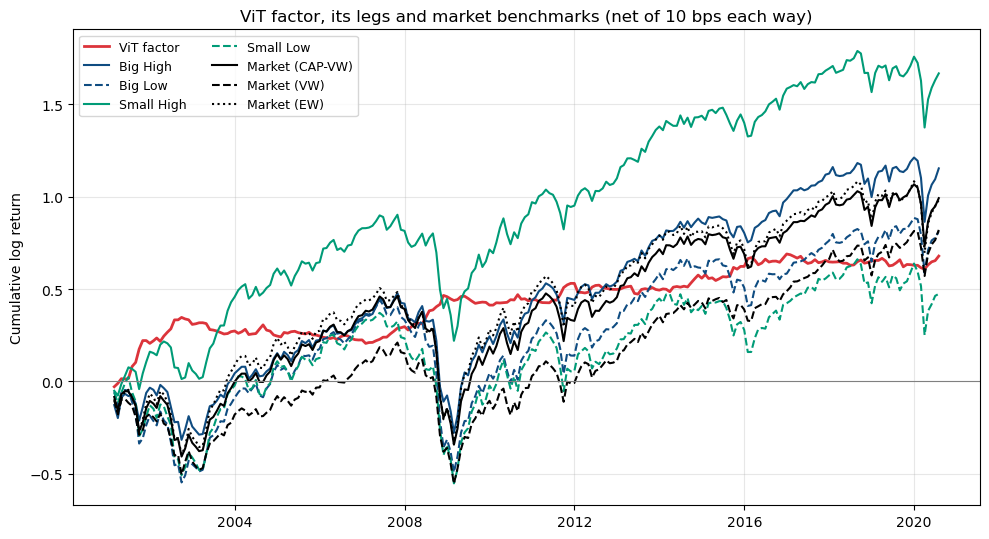

In [17]:
cum = np.log1p(all_series).cumsum()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(cum.index, cum["ViT"], color="#DC343B", linewidth=2, label="ViT factor")
ax.plot(cum.index, cum["Big_High"], color="#0f4c81", label="Big High")
ax.plot(cum.index, cum["Big_Low"], color="#0f4c81", linestyle="--", label="Big Low")
ax.plot(cum.index, cum["Small_High"], color="#009b77", label="Small High")
ax.plot(cum.index, cum["Small_Low"], color="#009b77", linestyle="--", label="Small Low")
ax.plot(cum.index, cum["CAP-VW"], color="black", label="Market (CAP-VW)")
ax.plot(cum.index, cum["VW"], color="black", linestyle="--", label="Market (VW)")
ax.plot(cum.index, cum["EW"], color="black", linestyle=":", label="Market (EW)")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_ylabel("Cumulative log return")
ax.set_title("ViT factor, its legs and market benchmarks (net of 10 bps each way)")
ax.legend(ncol=2, fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "cumulative_returns.png"), dpi=200)
plt.show()

### Factor alphas

A simple first check of whether the factor is new: regress its monthly return on standard
factors. The intercept (alpha) is the return the factors don't explain.

- **CAPM**: market excess return only.
- **FF5 + momentum**: market, size, value, profitability, investment and momentum.

t-statistics use Newey-West standard errors with 6 lags.

In [18]:
def alpha_regression(y, X, lags=NW_LAGS):
    data = pd.concat([y, X], axis=1).dropna()
    fit = sm.OLS(data.iloc[:, 0], sm.add_constant(data.iloc[:, 1:])).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return fit


y = factor_port["ViT"].copy()
y.index = months

capm = alpha_regression(y, ff5[["Mkt-RF"]])
ff6 = alpha_regression(y, pd.concat([ff5[["Mkt-RF", "SMB", "HML", "RMW", "CMA"]], mom["Mom"]], axis=1))

alphas = pd.DataFrame({
    "CAPM": [capm.params["const"] * 100, capm.tvalues["const"], capm.rsquared],
    "FF5 + Mom": [ff6.params["const"] * 100, ff6.tvalues["const"], ff6.rsquared],
}, index=["Monthly alpha (%)", "t-statistic", "R-squared"])

print(ff6.summary().tables[1])
alphas.round(3)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0023      0.001      2.093      0.036       0.000       0.004
Mkt-RF        -0.0069      0.036     -0.188      0.851      -0.078       0.064
SMB           -0.0623      0.039     -1.586      0.113      -0.139       0.015
HML           -0.0577      0.054     -1.059      0.289      -0.164       0.049
RMW            0.2368      0.073      3.241      0.001       0.094       0.380
CMA            0.0230      0.077      0.298      0.766      -0.128       0.174
Mom            0.0175      0.033      0.531      0.595      -0.047       0.082


,CAPM,FF5 + Mom
Monthly alpha (%),0.353,0.226
t-statistic,2.850,2.093
R-squared,0.054,0.153


## 7. Double-selection LASSO against 161 factors

### The idea

A stochastic discount factor (SDF) prices assets: a factor belongs in it if test-asset returns
line up with their covariance with that factor. The question is whether the ViT factor *g* adds
to the SDF after accounting for 161 known factors *h*.

Testing all 161 at once is impossible with about 235 months of data, and choosing controls by
hand invites bias. Feng, Giglio and Xiu (2020) select the controls with two LASSO regressions
and then run one OLS:

1. **First LASSO**: regress each test portfolio's average return on its covariances with the
   161 factors. This picks the factors that matter for pricing.
2. **Second LASSO**: regress each portfolio's covariance with the ViT factor on its covariances
   with the 161 factors. This picks the factors that look like the ViT factor.
3. **OLS**: regress average returns on covariances with the ViT factor plus the union of the
   factors from steps 1 and 2. A significant positive coefficient on the ViT factor means it
   has pricing power the known factors don't capture.

Step 2 is what makes it "double": a control that resembles the ViT factor is kept even if
step 1 missed it, so the ViT factor can't get credit for a known effect.

### Data

- **Test assets**: 1,958 portfolios sorted on anomaly signals (global-q.org), monthly returns in %.
- **Controls (161)**: 153 Global Factor Data factors, the Fama-French 5 factors and three q-factors.
- **Candidate**: the ViT factor, in %.

Everything is restricted to the months where the ViT factor exists.

In [19]:
kelly = load_monthly(os.path.join(FACTOR_DIR, "kelly_factor.csv"), date_col="date") * 100   # to percent
q5 = load_monthly(os.path.join(FACTOR_DIR, "q5.csv"), date_col="date")
test_ports = load_monthly(os.path.join(FACTOR_DIR, "test_portfolios.csv"), date_col="date")
ff5_pct = ff5 * 100

g_series = factor_port["ViT"].copy() * 100          # the ViT factor in percent
g_series.index = months

factor_zoo = pd.concat([kelly,
                        ff5_pct[["Mkt-RF", "SMB", "HML", "RMW", "CMA"]],
                        q5[["R_ME", "R_IA", "R_ROE"]]], axis=1)

common = g_series.index.intersection(factor_zoo.dropna().index).intersection(test_ports.index)
H = factor_zoo.loc[common].values                   # T x 161 control factors
g = g_series.loc[common].values                     # T     ViT factor
R = test_ports.loc[common].values                   # T x N test portfolio returns (may have NaN)
names = list(factor_zoo.columns)

print(f"Months: {len(common)} ({common.min()} to {common.max()}) | controls: {H.shape[1]} | test portfolios: {R.shape[1]}")

Months: 234 (2001-02 to 2020-07) | controls: 161 | test portfolios: 1958


### Covariances and penalty scaling

`cov_with(R, X)` returns, for every test portfolio, its covariance with each column of `X`,
using only the months where that portfolio has a return.

**Penalty scaling.** Factors that barely move test-asset returns produce tiny covariances, and
LASSO would treat them unfairly. Following the paper (Bryzgalova, 2015), each factor's
covariance column is multiplied by its mean squared univariate beta across test portfolios,
normalised to average 1. This is exactly what the authors' code does.

In [20]:
def cov_with(R, X):
    """N x K matrix: covariance of each test portfolio (column of R) with each column of X."""
    X = X.reshape(len(X), -1)
    out = np.full((R.shape[1], X.shape[1]), np.nan)
    for i in range(R.shape[1]):
        ok = np.isfinite(R[:, i])
        if ok.sum() < 3:
            continue
        xc = X[ok] - X[ok].mean(axis=0)
        yc = R[ok, i] - R[ok, i].mean()
        out[i] = yc @ xc / (ok.sum() - 1)
    return out


# Univariate betas of every test portfolio on every control factor: cov(R_i, h_k) / var(h_k)
cov_RH = cov_with(R, H)
betas = cov_RH / H.var(axis=0, ddof=1)
mean_sq_beta = np.nanmean(betas ** 2, axis=0)
penalty = mean_sq_beta / mean_sq_beta.mean()

print("Largest penalty weights:")
pd.Series(penalty, index=names).sort_values(ascending=False).head(10).round(3)

Largest penalty weights:


earnings_variability    5.338
ncol_gr1a               4.941
ni_inc8q                4.432
ni_ar1                  4.229
taccruals_ni            3.598
oaccruals_ni            3.548
qmj_safety              3.173
ebit_sale               2.694
taccruals_at            2.644
ebit_bev                2.642
dtype: float64

### Cross-validation for the two penalties

Each LASSO needs a penalty strength lambda. Following the paper:

- 100 values of lambda from e^0 down to e^-35.
- 10-fold cross-validation over months: covariances are recomputed on the training months and
  predictions are scored on the held-out months.
- Repeated over `N_SEEDS` random fold splits, and the error curves averaged.
- **1-SE rule**: pick the largest lambda whose average error is within one standard error of the
  minimum, with the standard error taken across seeds.

**Note.** The authors' selection code reads lambda positions as text, so its chosen index can
differ from the 1-SE rule described in the paper. This notebook applies the rule as written in
the paper.

**Run time.** Each seed fits 10 folds x 2 stages x 100 lambdas. `lasso_path` computes all 100
lambdas in one pass, and seeds run in parallel. With 200 seeds expect roughly 10 to 60 minutes,
depending on your CPU. Set `N_SEEDS = 20` for a first run.

In [21]:
def path_mse(X_tr, y_tr, X_te, y_te):
    """Fit the LASSO path on training data (with intercept) and return test MSE for every lambda."""
    ok_tr = np.isfinite(y_tr) & np.isfinite(X_tr).all(axis=1)
    ok_te = np.isfinite(y_te) & np.isfinite(X_te).all(axis=1)
    X_tr, y_tr, X_te, y_te = X_tr[ok_tr], y_tr[ok_tr], X_te[ok_te], y_te[ok_te]

    # Centering is the same as fitting an intercept
    x_mean, y_mean = X_tr.mean(axis=0), y_tr.mean()
    _, coefs, _ = lasso_path(X_tr - x_mean, y_tr - y_mean, alphas=LAMBDAS, max_iter=10_000, tol=1e-5)
    intercepts = y_mean - x_mean @ coefs                 # one intercept per lambda
    pred = X_te @ coefs + intercepts                     # N_test x 100
    return ((pred - y_te[:, None]) ** 2).mean(axis=0)


def cv_one_seed(seed):
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    mse1, mse2 = [], []
    for train, test in kf.split(H):
        # Training-month moments
        C_tr = cov_with(R[train], H[train]) * penalty
        mean_tr = np.nanmean(R[train], axis=0)
        g_tr = cov_with(R[train], g[train])[:, 0]
        # Held-out-month moments
        C_te = cov_with(R[test], H[test]) * penalty
        mean_te = np.nanmean(R[test], axis=0)
        g_te = cov_with(R[test], g[test])[:, 0]

        mse1.append(path_mse(C_tr, mean_tr, C_te, mean_te))   # stage 1: average returns
        mse2.append(path_mse(C_tr, g_tr, C_te, g_te))         # stage 2: covariance with ViT
    return np.mean(mse1, axis=0), np.mean(mse2, axis=0)


with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    cv_results = Parallel(n_jobs=N_JOBS)(delayed(cv_one_seed)(s) for s in tqdm(range(N_SEEDS), desc="CV seeds"))

cv_mse1 = np.array([r[0] for r in cv_results])   # N_SEEDS x 100
cv_mse2 = np.array([r[1] for r in cv_results])


def one_se_index(cv_mse):
    """Index of the largest lambda whose mean CV error is within one between-seed SE of the minimum."""
    mean_curve = cv_mse.mean(axis=0)
    best = int(np.argmin(mean_curve))
    se = cv_mse[:, best].std(ddof=1) / np.sqrt(len(cv_mse)) if len(cv_mse) > 1 else 0.0
    return int(np.argmax(mean_curve <= mean_curve[best] + se))   # first index = largest lambda


idx1, idx2 = one_se_index(cv_mse1), one_se_index(cv_mse2)
lam1, lam2 = LAMBDAS[idx1], LAMBDAS[idx2]
print(f"First LASSO:  log(lambda) = {np.log(lam1):.3f}")
print(f"Second LASSO: log(lambda) = {np.log(lam2):.3f}")

CV seeds: 100%|██████████| 200/200 [2:16:28<00:00, 40.94s/it]


First LASSO:  log(lambda) = 0.000
Second LASSO: log(lambda) = 0.000


### CV error curves

Average cross-validated error against log(lambda). The dashed line marks the chosen value.

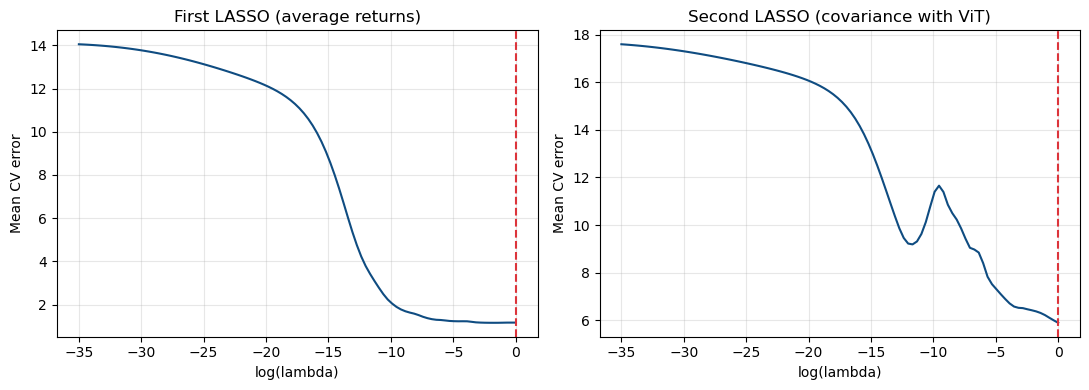

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, mse, idx, title in [(axes[0], cv_mse1, idx1, "First LASSO (average returns)"),
                            (axes[1], cv_mse2, idx2, "Second LASSO (covariance with ViT)")]:
    ax.plot(np.log(LAMBDAS), mse.mean(axis=0), color="#0f4c81")
    ax.axvline(np.log(LAMBDAS[idx]), color="#DC343B", linestyle="--")
    ax.set_xlabel("log(lambda)")
    ax.set_ylabel("Mean CV error")
    ax.set_title(title)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "lasso_cv_curves.png"), dpi=200)
plt.show()

### Final step: selected controls and the ViT factor's SDF loading

Fit both LASSOs on all months at the chosen lambdas, take the union of the selected controls,
then regress average test-portfolio returns on their covariances with the ViT factor and the
selected controls.

The coefficient on the ViT factor is its **SDF loading**. Positive and significant means the ViT
factor carries pricing information beyond the 161 controls. The t-statistic is from plain OLS,
as in the authors' code.

In [23]:
C_full = cov_RH * penalty                        # penalty-scaled covariances, all months
mean_R = np.nanmean(R, axis=0)
g_cov = cov_with(R, g)[:, 0]
ok = np.isfinite(mean_R) & np.isfinite(C_full).all(axis=1) & np.isfinite(g_cov)


def sdf_loading(lam_1, lam_2):
    """Run both LASSOs and the final OLS; return the fitted OLS model and the selected control names."""
    stage1 = Lasso(alpha=lam_1, fit_intercept=True, max_iter=10_000, tol=1e-5).fit(C_full[ok], mean_R[ok])
    stage2 = Lasso(alpha=lam_2, fit_intercept=True, max_iter=10_000, tol=1e-5).fit(C_full[ok], g_cov[ok])
    sel1 = [names[k] for k in np.flatnonzero(stage1.coef_)]
    sel2 = [names[k] for k in np.flatnonzero(stage2.coef_)]
    selected = sorted(set(sel1) | set(sel2))

    # Final OLS on unscaled covariances: selected controls plus the ViT factor (last column)
    cols = [names.index(c) for c in selected]
    X = np.column_stack([cov_RH[:, cols], g_cov])[ok]
    fit = sm.OLS(mean_R[ok], sm.add_constant(X)).fit()
    return fit, sel1, sel2, selected


fit, sel1, sel2, selected = sdf_loading(lam1, lam2)

print(f"First LASSO selected ({len(sel1)}): {sel1}")
print(f"Second LASSO selected ({len(sel2)}): {sel2}")
print(f"\nViT SDF loading: {fit.params[-1]:.4f}  (t = {fit.tvalues[-1]:.2f})")

First LASSO selected (0): []
Second LASSO selected (3): ['earnings_variability', 'qmj_safety', 'Mkt-RF']

ViT SDF loading: 0.0141  (t = 0.97)


### Robustness: how much does the answer depend on lambda?

Re-run the final step with each lambda shifted by -0.30 to +0.30 in log terms (steps of 0.05),
as in Figure 3 of the paper. A result that only holds at one exact lambda is fragile.

Sensitivity: 100%|██████████| 13/13 [00:02<00:00,  5.11it/s]


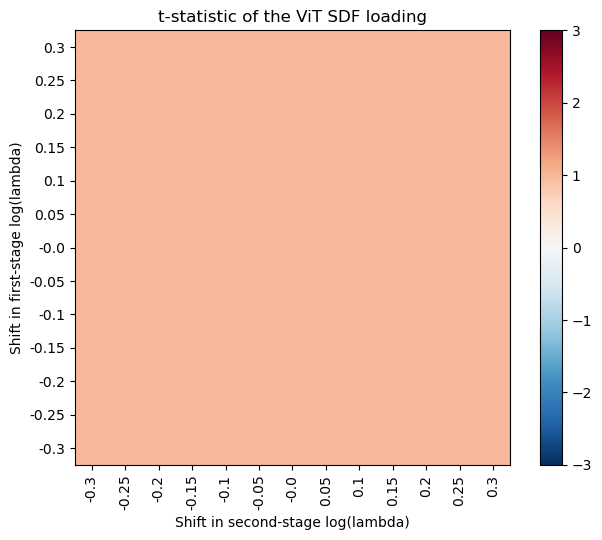

Share of grid with t > 1.96: 0%


In [24]:
shifts = np.round(np.arange(-0.30, 0.301, 0.05), 2)
t_grid = pd.DataFrame(index=shifts, columns=shifts, dtype=float)
for d1 in tqdm(shifts, desc="Sensitivity"):
    for d2 in shifts:
        f, *_ = sdf_loading(lam1 * np.exp(d1), lam2 * np.exp(d2))
        t_grid.loc[d1, d2] = f.tvalues[-1]

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(t_grid.values.astype(float), cmap="RdBu_r", vmin=-3, vmax=3, origin="lower")
ax.set_xticks(range(len(shifts)))
ax.set_xticklabels(shifts, rotation=90)
ax.set_yticks(range(len(shifts)))
ax.set_yticklabels(shifts)
ax.set_xlabel("Shift in second-stage log(lambda)")
ax.set_ylabel("Shift in first-stage log(lambda)")
ax.set_title("t-statistic of the ViT SDF loading")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "sdf_t_stat_sensitivity.png"), dpi=200)
plt.show()

print(f"Share of grid with t > 1.96: {(t_grid.values.astype(float) > 1.96).mean():.0%}")

## 8. Save results

In [25]:
panel.to_csv(os.path.join(OUT_DIR, "sorted_panel.csv"), index=False)
ports_3x3.to_csv(os.path.join(OUT_DIR, "portfolios_3x3.csv"))
ports_5x5.to_csv(os.path.join(OUT_DIR, "portfolios_5x5.csv"))
factor_port.to_csv(os.path.join(OUT_DIR, "vit_factor_Cap_VW.csv"))
benchmarks.to_csv(os.path.join(OUT_DIR, "benchmarks.csv"))
table1.to_csv(os.path.join(OUT_DIR, "table1_3x3_returns.csv"))
table_5x5.to_csv(os.path.join(OUT_DIR, "table_5x5_returns.csv"))
table2.to_csv(os.path.join(OUT_DIR, "table2_risk_metrics.csv"))
alphas.to_csv(os.path.join(OUT_DIR, "factor_alphas.csv"))
pd.DataFrame({"log_lambda": np.log(LAMBDAS), "cv_mse_stage1": cv_mse1.mean(axis=0),
              "cv_mse_stage2": cv_mse2.mean(axis=0)}).to_csv(os.path.join(OUT_DIR, "lasso_cv.csv"), index=False)
pd.DataFrame({
    "item": ["log_lambda_1", "log_lambda_2", "sdf_loading", "t_stat", "selected_stage1", "selected_stage2"],
    "value": [np.log(lam1), np.log(lam2), fit.params[-1], fit.tvalues[-1], "; ".join(sel1), "; ".join(sel2)],
}).to_csv(os.path.join(OUT_DIR, "sdf_loading.csv"), index=False)
t_grid.to_csv(os.path.join(OUT_DIR, "sdf_t_stat_sensitivity.csv"))

print("Saved to", os.path.abspath(OUT_DIR))
for f in sorted(os.listdir(OUT_DIR)):
    print(" ", f)

Saved to c:\Users\harol\OneDrive\Desktop\AI_and_ML_and_Quant_Finance\vit_stock_prediction\results
  benchmarks.csv
  cumulative_returns.png
  factor_alphas.csv
  lasso_cv.csv
  lasso_cv_curves.png
  portfolios_3x3.csv
  portfolios_5x5.csv
  sdf_loading.csv
  sdf_t_stat_sensitivity.csv
  sdf_t_stat_sensitivity.png
  sorted_panel.csv
  table1_3x3_returns.csv
  table2_risk_metrics.csv
  table_5x5_returns.csv
  vit_factor_Cap_VW.csv


## Limitations to keep in mind

- **Delisting returns are ignored.** A stock that delists during the holding month earns zero
  after its last trade instead of its delisting return. This matches the authors' code.
- **Image availability.** A chart image exists only when its 20-day label could be computed, so
  a stock that stopped trading within 20 days of a month end has no signal that month. That
  uses a little future information to decide who is in the sample.
- **Sample length.** Our sample is January 2001 to July 2020 (about 235 months), shorter than the
  paper's 288. Covariances and LASSO selections are noisier.
- **Trading cost.** A flat 10 bps each way with full turnover is a simplification. Micro caps
  cost far more to trade, which is one reason the factor leaves them out.